# SOCIAL NETWORK ANALYSIS

# Import thư viện

In [ ]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import community.community_louvain as community_louvain

# I. Phân tích Tổng quan Mạng (General Network Analysis)

## 1. Nguồn Dữ liệu và Tiền xử lý: 
Nguồn dữ liệu:

+ Dữ liệu được thu thập từ mạng xã hội Facebook.

+ Đối tượng: Các bình luận (comments) và phản hồi (replies) trong bài viết công khai có đường dẫn: "https://www.facebook.com/share/p/17aL7UkkCz/".

+ Phương pháp thu thập: Sử dụng ngôn ngữ Python với thư viện Selenium WebDriver.

+ Chiến thuật: Sử dụng kỹ thuật "Cuộn và Quét" (Scroll & Scan) kết hợp với việc tự động mở rộng các nút "Xem bình luận trước" và "Xem câu trả lời" để thu thập tối đa dữ liệu người dùng.

In [ ]:
# 1. Đọc dữ liệu thô
try:
    raw_nodes = pd.read_csv("database/fb_nodes.csv")
    raw_edges = pd.read_csv("database/fb_edges.csv")
    print(f"📄 Dữ liệu gốc: {len(raw_nodes)} nút, {len(raw_edges)} cạnh.")
except FileNotFoundError:
    print("❌ Không tìm thấy file. Hãy chắc chắn bạn đã chạy code cào dữ liệu trước.")
    exit()

In [ ]:
raw_nodes.head()

Bảng Nodes (Danh sách nút trong mạng) gồm 301 nút, liệt kê tất cả các thực thể xuất hiện trong mạng xã hội – bao gồm tài khoản người dùng, trang (page), hoặc các ID bài viết.
Mỗi hàng mô tả một node, với hai cột chính:

+ Id: mã định danh duy nhất của node (ví dụ: tên tài khoản, ID bài viết, ID trang).

+ Label: tên hiển thị hoặc nhãn mô tả ý nghĩa của node.

In [ ]:
raw_edges.head()

Bảng Edges (Các mối quan hệ giữa các node) có 412 cạnh, mô tả các kết nối (edges), cho thấy ai tương tác với ai hoặc sự liên kết giữa các node.
Mỗi kết nối gồm ba cột:

+ Source: nguồn của mối quan hệ (người tương tác, người tạo hoạt động).

+ Target: đích mà Source tác động tới (bài viết, trang hoặc tài khoản khác).

+ Type: kiểu kết nối — ở đây là Directed, nghĩa là mối quan hệ có hướng (A → B).

In [ ]:
# 2. Xử lý Nút (Nodes)
# Loại bỏ các ID trùng lặp (giữ lại người xuất hiện đầu tiên)
clean_nodes = raw_nodes.drop_duplicates(subset=['Id'], keep='first')

# 3. Xử lý Cạnh (Edges)
# 3.1. Loại bỏ Self-loops (Tự tương tác với chính mình)
clean_edges = raw_edges[raw_edges['Source'] != raw_edges['Target']]

# 3.2. Tính Trọng số (Weight)
# Gộp các dòng trùng nhau và đếm số lần xuất hiện
clean_edges = clean_edges.groupby(['Source', 'Target', 'Type']).size().reset_index(name='Weight')

# 4. Đồng bộ hóa (Quan trọng)
# Đảm bảo tất cả Source và Target đều có trong danh sách Nodes
# Lấy danh sách tất cả ID xuất hiện trong Edges
edge_ids = set(clean_edges['Source']).union(set(clean_edges['Target']))
# Lấy danh sách ID hiện có trong Nodes
node_ids = set(clean_nodes['Id'])

# Tìm những ID có trong Edges nhưng thiếu trong Nodes (Missing Nodes)
missing_ids = edge_ids - node_ids

# Nếu có thiếu, tạo Node giả lập cho họ (Lấy ID làm Label luôn)
if missing_ids:
    print(f"⚠️ Phát hiện {len(missing_ids)} IDs có trong Edges nhưng thiếu trong Nodes. Đang bổ sung...")
    missing_data = [{'Id': i, 'Label': str(i)} for i in missing_ids]
    missing_df = pd.DataFrame(missing_data)
    clean_nodes = pd.concat([clean_nodes, missing_df], ignore_index=True)

# 5. Lưu file sạch
clean_nodes.to_csv("database/fb_nodes_clean.csv", index=False)
clean_edges.to_csv("database/fb_edges_clean.csv", index=False)

print("-" * 30)
print("✅ TIỀN XỬ LÝ HOÀN TẤT!")
print(f"📊 Nodes sạch: {len(clean_nodes)}")
print(f"📊 Edges sạch: {len(clean_edges)} (Đã gộp trọng số)")
print("📂 File kết quả: 'database/fb_nodes_clean.csv' & 'database/fb_edges_clean.csv'")

## 2. Định nghĩa Đồ thị: 

### 2.1. Mô hình hóa mạng lưới (Graph Modeling)
Mạng xã hội từ bài viết Facebook được mô hình hóa dưới dạng một đồ thị $G = (V, E)$, trong đó:

+ Tập đỉnh (Nodes/Vertices - $V$): Đại diện cho các người dùng Facebook (Users) tham gia tương tác (bình luận hoặc phản hồi) trong bài viết. Mỗi người dùng duy nhất tương ứng với một nút trong đồ thị.

+ Tập cạnh (Edges/Links - $E$): Đại diện cho mối quan hệ tương tác (Interactions) giữa các người dùng. Một cạnh nối từ Nút A sang Nút B $(A \rightarrow B)$ được hình thành khi người dùng A phản hồi (reply) hoặc tương tác trực tiếp sau bình luận của người dùng B.

In [ ]:
# --- CẤU HÌNH ---
NODES_PATH = "database/fb_nodes_clean.csv"
EDGES_PATH = "database/fb_edges_clean.csv"

# 1. TẠO ĐỒ THỊ
print("--- ĐANG TẢI DỮ LIỆU ---")
nodes_df = pd.read_csv(NODES_PATH)
edges_df = pd.read_csv(EDGES_PATH)

# Tạo đồ thị Có hướng (DiGraph)
G = nx.from_pandas_edgelist(
    edges_df, 
    source='Source', 
    target='Target', 
    edge_attr='Weight', # Sử dụng trọng số đã tính ở bước tiền xử lý
    create_using=nx.DiGraph()
)

# Gắn thuộc tính Label cho nút (để hiển thị tên trên Gephi)
node_attr = nodes_df.set_index('Id')['Label'].to_dict()
nx.set_node_attributes(G, node_attr, 'label')

print(f"✅ Đồ thị đã tạo: {G.number_of_nodes()} nút, {G.number_of_edges()} cạnh.")

#### Phân loại kiểu đồ thị (Graph Taxonomy)
Dựa trên đặc điểm của dữ liệu thu thập, đồ thị mạng xã hội này được xác định là đồ thị có hướng, vì mối quan hệ phản hồi giữa người dùng mang tính một chiều: việc A trả lời B hoàn toàn khác với B trả lời A, do đó các cạnh được biểu diễn bằng mũi tên thể hiện luồng tương tác. Bên cạnh đó, đây là đồ thị có trọng số, trong đó trọng số cạnh phản ánh mức độ tương tác giữa hai người dùng — nếu họ đối đáp hoặc tranh luận nhiều lần, trọng số sẽ tăng lên, giúp phân biệt các tương tác hời hợt với các mối quan hệ mạnh hoặc tranh luận sâu. Cuối cùng, đồ thị này là đồng nhất, bởi tất cả các nút đều thuộc cùng một loại thực thể duy nhất: “người dùng Facebook”, không có sự pha trộn giữa các kiểu nút như bài viết hay hashtag, giúp mạng lưới tập trung hoàn toàn vào quan hệ giữa người dùng với nhau.

## 3. Phân tích tổng quan

In [ ]:
print("\n" + "="*30)
print("CÁC CHỈ SỐ TỔNG QUAN")
print("="*30)

# Mật độ (Density)
density = nx.density(G)
print(f"1. Mật độ mạng (Density): {density:.5f}")
if density < 0.1: print("   -> Nhận xét: Mạng thưa (Sparse Network).")
else: print("   -> Nhận xét: Mạng dày đặc.")

# Thành phần liên thông (Connected Components)
# Vì là đồ thị có hướng, ta xét "Liên thông yếu" (Weakly Connected) để xem tính lan truyền
weakly_components = list(nx.weakly_connected_components(G))
largest_cc_nodes = max(weakly_components, key=len)
H = G.subgraph(largest_cc_nodes).copy() # Tạo đồ thị con lớn nhất để tính đường kính
print(f"2. Số thành phần liên thông (Weakly): {len(weakly_components)}")
print(f"   -> Thành phần lớn nhất (Giant Component) chiếm: {len(H)/len(G)*100:.2f}% tổng số nút")

# Đường kính & Độ dài đường đi (Tính trên mạng vô hướng của thành phần lớn nhất cho dễ)
H_undirected = H.to_undirected()
try:
    diameter = nx.diameter(H_undirected)
    avg_path = nx.average_shortest_path_length(H_undirected)
    print(f"3. Đường kính (Diameter - khoảng cách xa nhất): {diameter}")
    print(f"4. Độ dài đường đi trung bình: {avg_path:.4f} (Lý thuyết 6 bậc phân cách)")
except:
    print("   (Đồ thị quá rời rạc để tính đường kính chính xác)")

# Hệ số phân cụm (Clustering Coefficient)
# Chuyển sang vô hướng để tính clustering xã hội
avg_clustering = nx.average_clustering(G.to_undirected())
print(f"5. Hệ số phân cụm trung bình: {avg_clustering:.4f}")

# --- BIỂU ĐỒ PHÂN PHỐI BẬC (POWER LAW) ---
print("\n--- Đang vẽ biểu đồ Phân phối bậc ---")
degrees = [d for n, d in G.degree()]
degree_counts = pd.Series(degrees).value_counts().sort_index()

plt.figure(figsize=(12, 6))

# Biểu đồ 1: Histogram
plt.subplot(1, 2, 1)
plt.hist(degrees, bins=30, color='skyblue', edgecolor='black')
plt.title("Phân phối bậc (Histogram)")
plt.xlabel("Bậc (Degree)")
plt.ylabel("Số lượng User")

# Biểu đồ 2: Log-Log Plot (Kiểm tra Power Law)
plt.subplot(1, 2, 2)
plt.loglog(degree_counts.index, degree_counts.values, 'b.', markersize=10)
plt.title("Phân phối bậc (Log-Log Scale)")
plt.xlabel("Bậc (Log)")
plt.ylabel("Tần suất (Log)")
plt.grid(True, which="both", ls="-", alpha=0.5)

plt.tight_layout()
plt.savefig("database/degree_distribution.png") # Lưu ảnh
print("✅ Đã lưu biểu đồ: database/degree_distribution.png")
plt.show() # Bật dòng này nếu muốn xem luôn

Biểu đồ Histogram (bên trái): thể hiện số lượng người dùng (user) tương ứng với từng bậc kết nối (degree). Mỗi bậc (degree): là số lượng liên kết (edges) mà một user có — ví dụ: số lần người đó được tag, trả lời, hoặc tương tác với người khác trong mạng lưới.

Trong biểu đồ, ta thấy: Bậc 2 chiếm số lượng lớn nhất (hơn 200 người). Một số user có bậc 3–4, thể hiện nhóm có mức độ tương tác trung bình. Tuy nhiên bậc 5–8 xuất hiện rất ít, chỉ vài người.

→ Đa số người dùng chỉ tương tác rất ít (1–2 kết nối). Chỉ có một nhóm nhỏ tương tác nhiều hơn, tạo ra cấu trúc mạng theo kiểu phân bố lệch (skewed distribution).

Biểu đồ Log–Log (bên phải): Biểu đồ này biểu diễn tần suất xuất hiện của mỗi bậc trên thang đo logarit (log-log scale).

+ Trục X: bậc (log).

+ Trục Y: tần suất (log).

+ Dạng biểu đồ gần như đi theo đường thẳng và dốc xuống.

→ Có Ý nghĩa quan trọng. Là đặc trưng của mạng xã hội dạng Scale-Free (mạng không tỷ lệ), nơi mà một số rất ít user có mức độ tương tác cực cao → “hub”, đa số còn lại có tương tác rất nhỏ. Điều này đúng với thực tế: trên Facebook, hầu hết người dùng chỉ bình luận 1–2 lần, nhưng một vài tài khoản nổi bật (như chủ bài viết, kênh giải trí, admin) sẽ có bậc rất cao.

Kết luận:
Hai biểu đồ cho thấy cấu trúc mạng xã hội dưới bài viết mang đặc trưng lệch mạnh. Phần lớn người dùng chỉ tương tác ở mức thấp (bậc 1–2), trong khi chỉ có một nhóm rất nhỏ sở hữu số lượng kết nối cao. Dạng phân bố này gần tương ứng với Power-Law, một mô hình thường gặp trong các mạng xã hội như Facebook, nơi số lượng lớn người dùng hoạt động thưa thớt và chỉ một số ít giữ vai trò trung tâm. Nhóm người dùng có bậc cao chính là những nhân tố quan trọng trong cuộc thảo luận — có thể là chủ bài viết, các tài khoản ảnh hưởng (influencers), hoặc những người tạo ra các luồng tranh luận mạnh — và họ quyết định đáng kể đến sự lan truyền và mức độ sôi động của tương tác dưới bài viết.

### 3.1. Thống kê kích thước mạng lưới (Network Size)

+ Số lượng Nút (Nodes): 301 (người dùng).

+ Số lượng Cạnh (Edges): 367 (cặp tương tác).

+ Mật độ mạng (Density): 0.00406. 

Công thức:
$D = \frac{E}{N(N-1)}$ (với đồ thị có hướng), trong đó $E$ là số cạnh thực tế và $N$ là số nút.

Nhận xét: 

1. Đánh giá định lượng: Với giá trị mật độ $D \approx 0.004$ (hay 0.4%), mạng lưới xã hội này được phân loại là một Mạng thưa (Sparse Network). Điều này nghĩa là trong tổng số 90.300 mối quan hệ có thể xảy ra giữa 301 người dùng $(N \times (N-1))$, chỉ có 367 mối quan hệ thực sự được hình thành.

2. Ý nghĩa về mặt xã hội học: Chỉ số mật độ thấp này phản ánh đặc thù hành vi tương tác trong các bài đăng công khai trên Facebook:
+ Tính tập trung (Centralized Interaction): Sự tương tác không lan tỏa đều. Phần lớn người dùng tham gia chỉ để tương tác với một vài cá nhân cụ thể (thường là tác giả bài viết hoặc một người có bình luận nổi bật), thay vì tương tác chéo với nhau.

+ Thiếu sự gắn kết cộng đồng (Low Cohesion): Mạng lưới chưa hình thành được một cộng đồng chặt chẽ nơi "mọi người đều biết mọi người". Thay vào đó, nó là tập hợp của nhiều chuỗi hội thoại rời rạc hoặc các cụm nhỏ lẻ tẻ.

+ Mô hình Tương tác: Có xu hướng thiên về mô hình "Ngôi sao" (Star topology) – nơi một số ít người (Hub) nhận được phần lớn sự chú ý, trong khi đa số các thành viên còn lại (các nút lá) chỉ có 1 tương tác duy nhất rồi rời đi.

→ Mặc dù số lượng người tham gia khá đông (301 người), nhưng sự kết nối giữa họ rất lỏng lẻo. Đây là một mạng lưới thông tin (information network) điển hình hơn là một mạng lưới xã hội thân thiết (social network).

### 3.2. Phân tích cấu trúc

In [ ]:
# ==========================================================
# PHÂN TÍCH CẤU TRÚC (CENTRALITY)
# ==========================================================
print("\n" + "="*30)
print("NGƯỜI CÓ TẦM ẢNH HƯỞNG (CENTRALITY)")
print("="*30)

# Tính toán các chỉ số
deg_cent = nx.degree_centrality(G)
in_cent = nx.in_degree_centrality(G) # Quan trọng: Ai được reply nhiều nhất?
page_rank = nx.pagerank(G, weight='Weight') # Quan trọng: Ai có uy tín nhất?
bet_cent = nx.betweenness_centrality(G) # Quan trọng: Ai là cầu nối thông tin?

# Tạo bảng so sánh
centrality_df = pd.DataFrame({
    'Name': [G.nodes[n]['label'] for n in G.nodes()],
    'Degree': pd.Series(deg_cent),
    'In_Degree (Được quan tâm)': pd.Series(in_cent),
    'PageRank (Uy tín)': pd.Series(page_rank),
    'Betweenness (Cầu nối)': pd.Series(bet_cent)
})

# In ra Top 5 Influencers theo PageRank
print("\nTOP 5 NGƯỜI CÓ TẦM ẢNH HƯỞNG (PAGERANK):")
print(centrality_df.sort_values('PageRank (Uy tín)', ascending=False).head(5)[['Name', 'PageRank (Uy tín)']])

print("\nTOP 5 NGƯỜI ĐƯỢC TRẢ LỜI NHIỀU NHẤT (IN-DEGREE):")
print(centrality_df.sort_values('In_Degree (Được quan tâm)', ascending=False).head(5)[['Name', 'In_Degree (Được quan tâm)']])

# Tương quan giữa các chỉ số
print("\nMA TRẬN TƯƠNG QUAN GIỮA CÁC CHỈ SỐ:")
print(centrality_df[['Degree', 'PageRank (Uy tín)', 'Betweenness (Cầu nối)']].corr())


### 3.4 Phân tích cộng đồng

In [ ]:
# ==========================================================
# PHÂN TÍCH CỘNG ĐỒNG (COMMUNITY DETECTION)
# ==========================================================
print("\n" + "="*30)
print("PHÁT HIỆN CỘNG ĐỒNG (LOUVAIN)")
print("="*30)

# Louvain hoạt động tốt nhất trên đồ thị vô hướng
G_undirected = G.to_undirected()
partition = community_louvain.best_partition(G_undirected)

# Tính Modularity (Độ phân tách cộng đồng)
modularity = community_louvain.modularity(partition, G_undirected)
print(f"1. Tính Mô-đun (Modularity): {modularity:.4f}")
if modularity > 0.3: print("   -> Mạng lưới có cấu trúc cộng đồng rõ rệt.")
else: print("   -> Cộng đồng không rõ ràng.")

# Đếm số lượng cộng đồng
num_communities = len(set(partition.values()))
print(f"2. Số lượng cộng đồng phát hiện được: {num_communities}")

# Thêm thông tin cộng đồng vào đồ thị để xuất ra Gephi
nx.set_node_attributes(G, partition, 'Modularity Class')

# Thêm thông tin PageRank vào đồ thị luôn
nx.set_node_attributes(G, page_rank, 'PageRank')

In [ ]:
# ==========================================================
# XUẤT FILE CHO GEPHI
# ==========================================================
print("\n" + "="*30)

OUTPUT_FILE = "database/facebook_network_final.gexf"
nx.write_gexf(G, OUTPUT_FILE)
print(f"✅ ĐÃ XUẤT FILE GEPHI: {OUTPUT_FILE}")
print("👉 Hãy mở file này bằng phần mềm Gephi để thực hiện bước 'Bố cục mạng' và làm Slide.")
print("="*30)

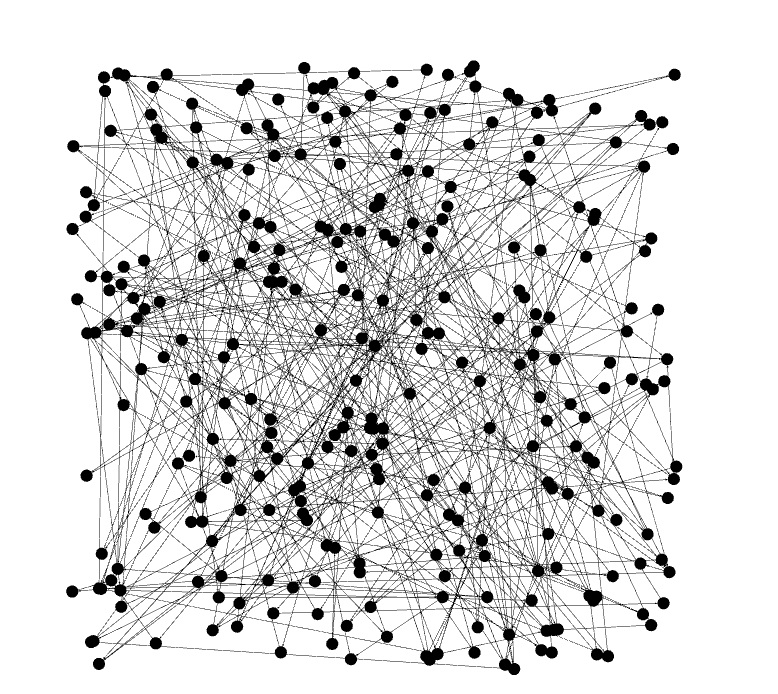

Hình ảnh đồ thị mở bằng Gephi